# 系数校准与留出验证

输出校准实验；10–12 Hz 拟合，13–15 Hz 验证。并非修改气动参数后的重跑。

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
here=Path.cwd().resolve()
ROOT=next(p for p in (here,*here.parents) if (p/'flapsim/simulator.py').exists())
sys.path.insert(0,str(ROOT/'experiments/fixbase_curved_real'))
from coefficient_validation import main, OUTPUT
result=main()
report=(OUTPUT/'report.md').read_text()
display(Markdown(report.replace('![平均升力校准](lift_gain_holdout.png)','').replace('![周期波形](force_gain_waveforms.png)','')))

{
  "lift": {
    "shared": {
      "gain": 1.2767171289084434,
      "training_hz": [
        10,
        11,
        12
      ],
      "held_out_hz": [
        13,
        14,
        15
      ],
      "train_mape_pct": 8.843246066686424,
      "train_max_abs_error_pct": 16.626141524638104,
      "test_mape_pct": 12.389483912346746,
      "test_max_abs_error_pct": 16.731440574575895
    },
    "curve": {
      "gain": 1.1247385927502145,
      "training_hz": [
        10,
        11,
        12
      ],
      "held_out_hz": [
        13,
        14,
        15
      ],
      "train_mape_pct": 3.4281399771725916,
      "train_max_abs_error_pct": 6.450225352894002,
      "test_mape_pct": 2.638493510508111,
      "test_max_abs_error_pct": 2.8359009437000315
    },
    "rect": {
      "gain": 1.3421624688986311,
      "training_hz": [
        10,
        11,
        12
      ],
      "held_out_hz": [
        13,
        14,
        15
      ],
      "train_mape_pct": 1.1916475911645612,


# 系数能否解决实测与仿真误差？

## Material Passport
模式：已有实验结果的描述性校准检查。Verification Status: ANALYZED。
使用两翼型各 18 次实测及此前 ±26.1°、单翼、固定基座仿真。原始记录及物理模型均未修改。
本次是输出系数拟合，不是修改气动系数后的动力学重跑。

## 结论
**每种翼型各用一个系数，可以改善平均 Fz 在本次 10–15 Hz 范围内的预测；不能据此认定 feathering angle 是误差来源，也不能证明六维力准确。**
两种翼型需要不同系数；周期波形与均值需要的系数也不同。校准不能自动转移到其他翼型、运动状态或力矩。

## 1. 平均升力：用留出频率检验
模型为 Fz_corrected=k Fz_sim，k≥0，无截距。仅使用 10、11、12 Hz 的三次重复均值拟合，13、14、15 Hz 固定 k 后评价。
两个翼型共用系数时按力的平方误差最小化，较大升力的矩形翼权重自然较大；不是按各点百分比加权。
下表不代表总体误差保证，也未预设“准确”阈值。

|系数适用范围|10–12 Hz 拟合 k|13–15 Hz 平均绝对相对误差|最大绝对相对误差|
|---|---:|---:|---:|
|曲面翼|1.1247|2.64%|2.84%|
|矩形翼|1.3422|3.57%|4.48%|
|两翼型共用|1.2767|12.39%|16.73%|



三次重复误差棒是 SD，不是校准置信区间。基线继续采用运动段 0.5–4 s 减尾段 5.5 s 至末尾前 0.1 s；停机去皮假设仍待确认。
`lift_holdout.csv` 含所有点及校正前后数值；`summary.json` 还列出跨翼型迁移误差。

## 2. 平均值校准不等于周期载荷校准
坐标 yaw 固定为此前只用 10–12 Hz 拟合的候选值：曲面 −27.5°，矩形 −31.5°。Z 保持不变。
每次记录沿用同一个此前确定的时间相位；不为不同校正方式重新优化相位或 yaw。
比较 1–4 阶周期波形，使用总线动量重建仿真支座惯性反力。留出记录仍允许此前的时间对齐，并非绝对时钟预测。

|翼型|平均 Fz 系数|周期 Fx 系数|周期 Fy 系数|周期 Fz 系数|
|---|---:|---:|---:|---:|
|curve|1.125|1.088|1.240|1.231|
|rect|1.342|0.886|1.035|1.424|

|翼型|校正方式|Fx NRMSE|Fy NRMSE|Fz NRMSE|三轴向量 NRMSE|
|---|---|---:|---:|---:|---:|
|curve|原始|62.4%|53.3%|72.4%|59.5%|
|curve|平均升力系数乘整个力|61.4%|50.0%|69.9%|57.4%|
|curve|仅缩放气动力，运动固定|64.7%|53.9%|70.6%|60.7%|
|curve|周期力拟合单系数|61.3%|49.1%|69.3%|57.0%|
|curve|逐轴拟合（诊断）|61.6%|47.9%|68.7%|56.6%|
|rect|原始|52.5%|57.9%|93.5%|65.3%|
|rect|平均升力系数乘整个力|62.8%|60.8%|91.3%|68.8%|
|rect|仅缩放气动力，运动固定|65.0%|64.5%|91.3%|71.0%|
|rect|周期力拟合单系数|52.5%|58.0%|93.6%|65.3%|
|rect|逐轴拟合（诊断）|52.8%|57.7%|91.1%|64.6%|

单轴 NRMSE=RMSE/实测该轴交流 RMS；向量 NRMSE 按三轴合并 RMS 归一化，均先逐次记录计算再平均。
非零均值误差仍包含在 RMSE 中。上述分母使小幅轴更敏感，因此同时在 CSV 保存 mN 的绝对 RMSE。
逐轴系数是较宽松的诊断，不是统一物理修正；它仍不能改变谐波比例、峰形、相位关系。



“整个力乘系数”会同时放大机构惯性载荷；这不是单纯调整气动系数。
“只缩放气动力”一项使用 F_fixture,new=F_fixture,old+(k−1)F_aero,old，保留既有运动，
是固定运动条件下的诊断。真实修改流体参数会改变被动羽化轨迹，需要再求解动力学，不能把此项称为已验证新物理模型。

## 3. 为什么不能由系数推出 feathering angle
平均力是整个周期气动力的积分。几何、速度、气动系数、羽化时序、形变以及测量基线的差异，都可能表现为平均值的比例误差。
目前只知道羽化限位 ±26.1°；它不能给出真实 α(t)、换向时间或角速度。乘上 k 没有识别这些运动变量。
即使平均值完全重合，峰值、谐波和六维载荷仍可能不同。因此可暂用经验系数估计此范围内的平均升力，不能以此忽略羽化运动验证。

## 4. 六维力矩的条件检查
六维量为 [Fx,Fy,Fz,Mx,My,Mz]。力矩需要统一测量原点：转换包含旋转及 r×F 项，不能只旋转坐标或乘系数。
传感器相对 base_link 的位置、静态去皮姿态尚未提供。此前 2 kHz 直接支座力矩还可能受限位冲击采样影响，未记录可用于稳定重建的总角动量。
因此本次 **不将三个力矩分量判为已验证**。

为检查“一个比例系数能否解释全部均值”，在假设原点重合、重力基线已消除的条件下，也计算了每轴各自的系数：

|翼型|分量|单独均值拟合的非负系数（条件诊断）|
|---|---|---:|
|curve|Fx|1.6|
|curve|Fy|0.241|
|curve|Fz|1.12|
|curve|Mx|0.819|
|curve|My|0.828|
|curve|Mz|0|
|rect|Fx|2.02|
|rect|Fy|0.378|
|rect|Fz|1.34|
|rect|Mx|1.11|
|rect|My|1.17|
|rect|Mz|0|

这里只把仿真气动平均力矩作为条件预测；实际支座力矩还可能含运动导致的平均重力矩变化。
系数为零表示非负最小二乘落在边界（例如符号相反），不能解释成真实材料/传感器增益为零。
这一表用于暴露统一系数假设的限制，不能据此给力矩传感器重新标定。

## 可支持的表述
“针对当前单翼固定基座工况，在 10–12 Hz 标定每种翼型的平均升力修正系数后，13–15 Hz 的平均 Fz 误差为上表所列范围。”
目前不支持“误差已经确定来自羽化角，可忽略其影响，仿真能够准确获得六维力”。

## 检查与复现
11/11 统计解释检查：分翼型报告以避免混合趋势；重复实验而非采样点作为单位；全纳入无选择/幸存者筛除；
无碰撞变量控制、诊断基率或极值筛选前后比较；所有频率/轴/拟合方式公开；探索性校准不作因果或反向因果推断；
拟合/留出频率分开，没有使用留出力数据更新系数。共计零项显著性检验。
全部结论继承此前的质量、翼膜边界、安装偏移、频率不同步和尾段基线假设。

```bash
python experiments/fixbase_curved_real/coefficient_validation.py
```

`summary.json` 包含输入与分析脚本哈希。此分析不覆盖既有的原始实验或未校正仿真结果。


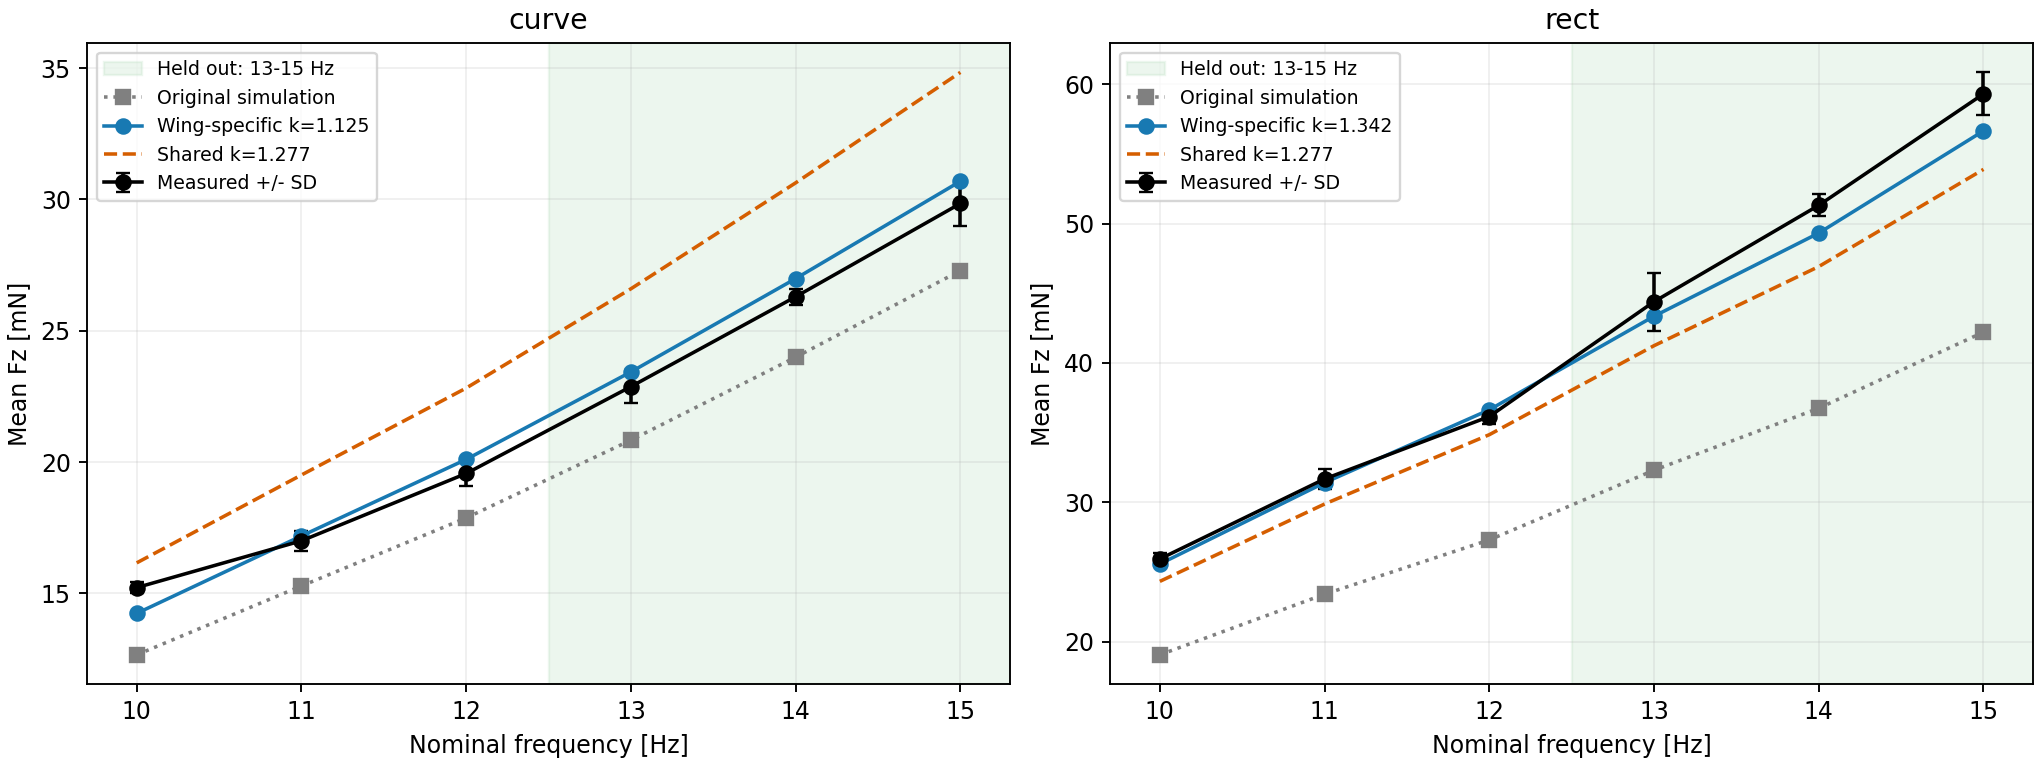

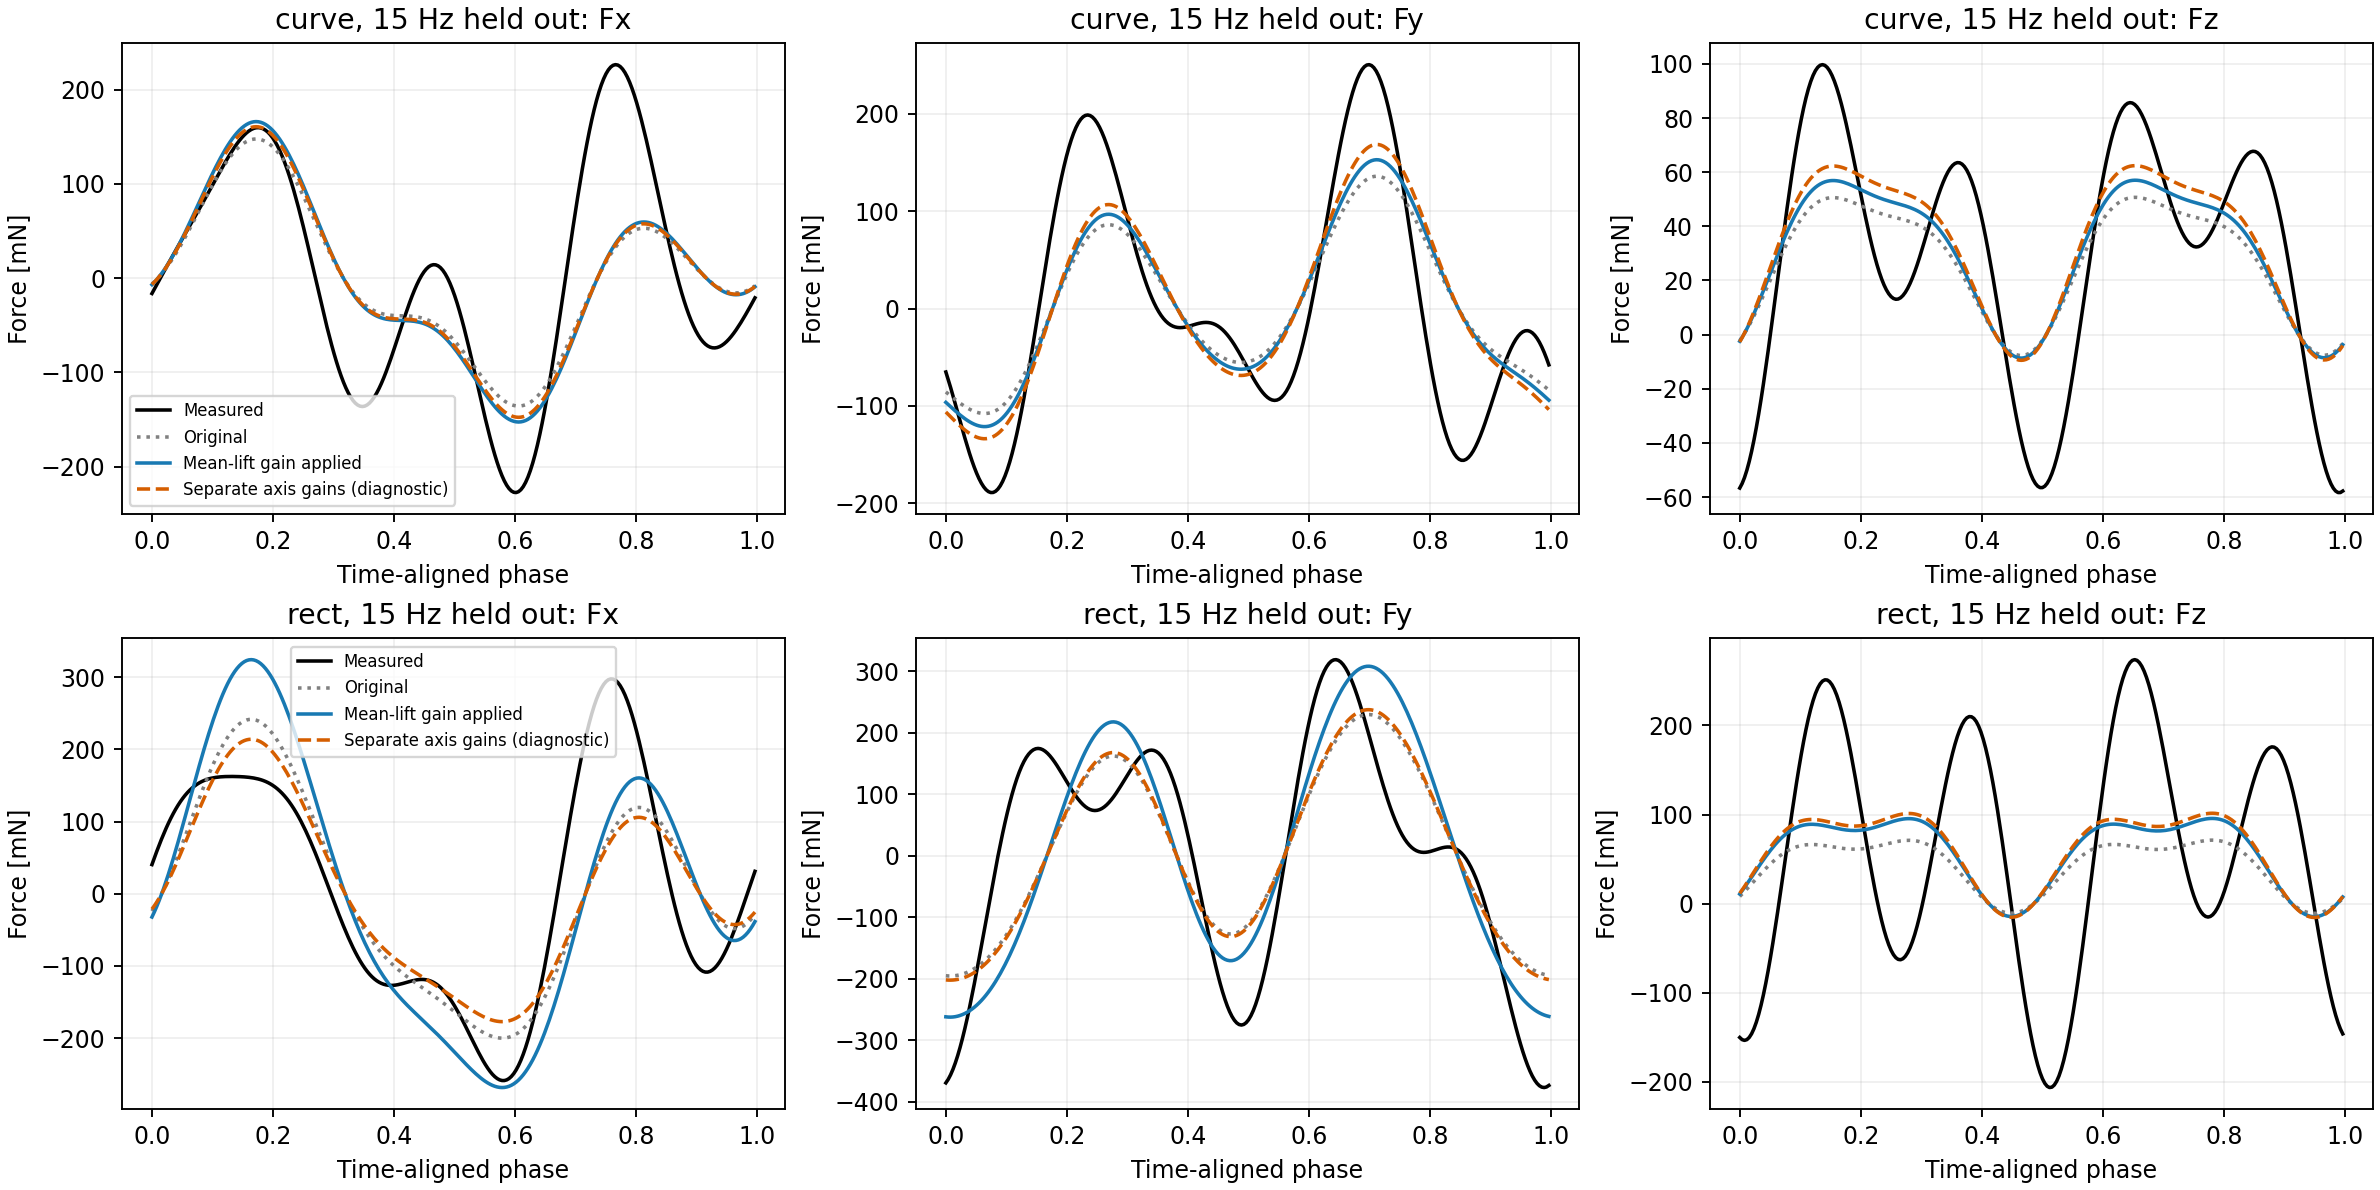

In [2]:
display(Image(filename=str(OUTPUT/'lift_gain_holdout.png')))
display(Image(filename=str(OUTPUT/'force_gain_waveforms.png')))